> **Quellversion für Lehrkräfte** (enthält alle drei Niveaus). Die Versionen für die Lernenden (`_gruen`, `_gelb`, `_rot`) werden daraus mit
> `python3 material/quelle/schuelerversion_erstellen.py` erzeugt. Zellen mit dem Tag `niveau-…` erscheinen nur im jeweiligen Niveau. In Code-Zellen gilt: Zeilen zwischen `# >>> LOESUNG` und `# <<< LOESUNG` sind die Lösung (Version grün), `# GELB| …` ist der Pseudocode für gelb, `# | …` der Platzhalter für rot.

In [1]:
# Nur in der Lehrkraft-Version: Hilfsmodul aus dem übergeordneten Ordner finden
import sys
sys.path.insert(0, "..")

# 10 – Bilddaten verstehen und ein erstes neuronales Netz trainieren

**Lernsituation „KI-Sichtprüfstation“ · Doppelstunden 1 bis 4**

In diesem Notebook gehen Sie den ganzen Weg einmal durch: von den Kamerabildern bis zur ersten Vorhersage einer KI.

**Ziele – am Ende können Sie …**
- erklären, wie eine KI aus Beispielen lernt,
- erklären, wie ein Bild im Computer gespeichert ist,
- Bilder laden, verkleinern und für das Training vorbereiten,
- ein kleines neuronales Netz bauen, trainieren und testen.

| Teil | Doppelstunde | Inhalt |
|---|:--:|---|
| A | 1 | Die Prüfstation, Grundbegriffe, eigene Bilder aufnehmen |
| B | 2 | Bilder als Zahlen, Bilder laden und vorbereiten, Teilzielkontrolle 1 |
| C | 3 | Neuron, Softmax, das erste Netz bauen |
| D | 4 | Training, Test, Vorhersage für ein einzelnes Bild |

**So arbeiten Sie:** Klicken Sie in eine Zelle und drücken Sie **Umschalt + Enter**. Führen Sie die Zellen immer **von oben nach unten** aus.

**Ihr Niveau: GRÜN.** Der gesamte Code ist fertig. Sie führen die Zellen aus, beobachten das Ergebnis und beantworten die Fragen unter **[Frage]**.

**Ihr Niveau: GELB.** In den Aufgaben steht in einfachen Worten, was der Code tun soll (Pseudocode). Sie schreiben unter jede Kommentarzeile den passenden Python-Befehl. Die Befehle, die Sie brauchen, stehen jeweils über der Aufgabe.

**Ihr Niveau: ROT.** In den Aufgaben schreiben Sie den Code selbst. Es gibt nur kurze Hinweise. Unter jeder Aufgabe zeigt eine Kontrolle, ob Ihr Ergebnis stimmt.

**So lesen Sie dieses Notebook**

| Kennzeichen | Bedeutung |
|---|---|
| **[Lesen]** | Grundlagen – lesen oder interaktiv ausprobieren |
| **[Aufgabe]** | Code ausführen, ergänzen oder selbst schreiben |
| **[Frage]** | Frage beantworten – schriftlich oder im Gespräch |
| **[Test]** | Teilzielkontrolle |
| **[Industrie]** | Bezug zur Fertigung |
| **[Raspberry Pi]** | Hinweis für den Raspberry Pi |

---
## Teil A – Die KI-Sichtprüfstation (Doppelstunde 1)

### [Lesen] Der Auftrag
Ein Zulieferbetrieb möchte am Ende einer Montagelinie eine **günstige KI-Prüfstation** einsetzen. Eine Kamera fotografiert jedes Teil. Ein Raspberry Pi erkennt, welches Teil es ist, und zeigt das Ergebnis an.

Zuerst bauen wir einen **Prototyp mit vier Symbolen**: 
- Kreuz, 
- Kreis, 
- Dreieck und 
- Quadrat. 
Sie stehen stellvertretend für verschiedene Bauteile oder Prüfergebnisse.

Führen Sie die nächste Zelle aus und probieren Sie die Prüfstation aus.

In [2]:
# Werkzeuge laden – diese Zelle einfach ausführen (Umschalt + Enter)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ki_hilfen as kh

kh.zeige_html("00_szenario_pruefstation.html")

### [Lesen] Wie lernt eine KI?

| | Klassisches Programm | Maschinelles Lernen (KI) |
|---|---|---|
| Der Mensch gibt vor … | **Regeln**, z. B. „4 Ecken → Quadrat“ | **viele Beispiele** mit der richtigen Antwort |
| Das Ergebnis ist … | ein Programm | ein **trainiertes Modell** |
| Schwierig wird es bei … | Schatten, schiefen Linien, Handschrift | zu wenigen oder schlechten Beispielen |

Bei uns heißt das: Wir zeigen der KI viele Fotos von Kreuzen, Kreisen, Dreiecken und Quadraten. Zu jedem Foto sagen wir ihr, was darauf zu sehen ist (das **Label**). Daraus lernt sie selbst, woran man die Formen erkennt. Das nennt man **überwachtes Lernen**.

![Pipeline](../material/bilder/pipeline.svg)

### [Aufgabe] Eigene Bilder aufnehmen
Das Programm `00_Datensatz_aufnehmen.py` speichert jedes Kamerabild direkt im Ordner seiner Klasse:

```
dataset_neu/
  klassen.txt      → 0;Kreuz  1;Kreis  2;Dreieck  3;Quadrat
  0/  1/  2/  3/   → die Bilder jeder Klasse
```

**Start im Terminal** (im Ordner `datasets/symbols`):
```bash
python3 00_Datensatz_aufnehmen.py --datensatz dataset_gruppe1
```
Im Kamerafenster: Taste **0, 1, 2 oder 3** speichert das Bild in dieser Klasse. **z** löscht die letzte Aufnahme, **ESC** beendet.

**Achten Sie bei der Aufnahme auf:**
- gleiches Licht wie später an der Station
- verschiedene Lagen, Drehungen und Größen der Symbole
- ungefähr gleich viele Bilder je Klasse (mindestens 50)
- verschiedene Personen zeichnen die Symbole

[Industrie] In der Fertigung gilt dasselbe: Die KI erkennt nur zuverlässig, was sie beim Lernen gesehen hat.

### [Frage]
1. Was macht die Kamera, was macht die KI?
2. Warum braucht die KI viele verschiedene Beispielbilder?
3. Was passiert vermutlich, wenn alle Trainingsbilder bei Tageslicht aufgenommen wurden, die Station später aber im Dunkeln mit Lampe arbeitet?

*Ihre Antworten (Doppelklick zum Schreiben):*

### [Aufgabe] Den Datensatz anschauen
Wir arbeiten zuerst mit dem kleinen Datensatz `dataset1` (176 Bilder). Später können Sie Ihren eigenen Datensatz eintragen.

Klassen: ['Kreuz', 'Kreis', 'Dreieck', 'Quadrat']


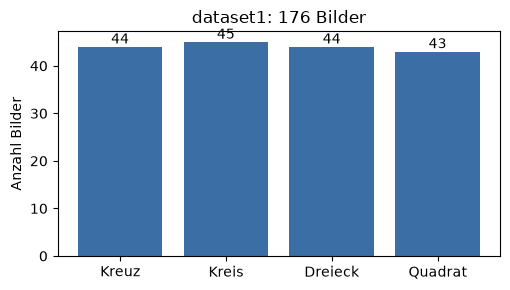

In [3]:
DATENSATZ = "dataset1"                    # Name des Ordners mit den Bildern

klassen = kh.lese_klassen(DATENSATZ)      # Namen der Klassen aus klassen.txt
print("Klassen:", klassen)
kh.zeige_anzahl(DATENSATZ)                # Balkendiagramm: Bilder je Klasse

---
## Teil B – Ein Bild ist eine Tabelle aus Zahlen (Doppelstunde 2)

### [Lesen] Was bekommt die KI?

In [4]:
kh.zeige_html("01_bild_als_zahlen.html")

### [Lesen] Matrix und Vektor
Ein Bild ist eine **Matrix** (Tabelle mit Zeilen und Spalten). Ein einfaches neuronales Netz braucht aber einen **Vektor** (eine einzige Zahlenreihe). Schauen Sie sich an, wie aus der Matrix ein Vektor wird.

In [5]:
kh.zeige_html("01b_matrix_zu_vektor.html")

### [Aufgabe] Ein Kamerabild laden
`cv2.imread()` lädt ein Bild. Das Ergebnis ist eine Tabelle aus Zahlen mit der Form **(Höhe, Breite, Farbkanäle)**.

**Achtung:** OpenCV speichert die Farben in der Reihenfolge **Blau, Grün, Rot** (BGR). Die meisten anderen Programme erwarten **Rot, Grün, Blau** (RGB). Vertauscht man das, sehen die Farben falsch aus.

Form des Bildes: (480, 640, 3)
kleinster Wert: 0   größter Wert: 240


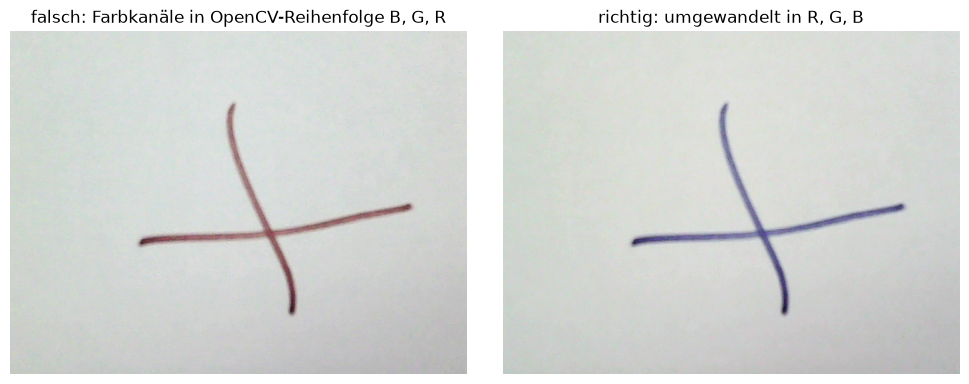

In [6]:
dateien = kh.bilddateien(DATENSATZ + "/0")     # alle Bilder der Klasse 0
bild = cv2.imread(str(dateien[0]))             # das erste Bild laden

print("Form des Bildes:", bild.shape)
print("kleinster Wert:", bild.min(), "  größter Wert:", bild.max())
kh.zeige_bgr_rgb(bild)

### [Frage]
1. Wie hoch und wie breit ist das Bild? Was bedeutet die dritte Zahl der Form?
2. Wie viele Zahlen hat dieses Bild insgesamt? (Höhe × Breite × 3)

*Ihre Antworten:*

### [Aufgabe B1] Das Bild verkleinern
640 × 480 Pixel in Farbe sind fast eine Million Zahlen – zu viel für unser erstes Netz. Wir machen das Bild deshalb **grau** und **klein (32 × 32 Pixel)**.

Lesen Sie den Code und führen Sie die Zelle aus.

**Befehle, die Sie brauchen:**
- Farbbild in Graustufen umwandeln: `cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)`
- Bild verkleinern: `cv2.resize(bild, (breite, hoehe))`

Ersetzen Sie jedes `None` durch den passenden Befehl.

Wandeln Sie `bild` in ein Graustufenbild `grau` um und verkleinern Sie es auf 32 × 32 Pixel (`klein`). Hinweis: OpenCV-Funktionen `cvtColor` und `resize`.

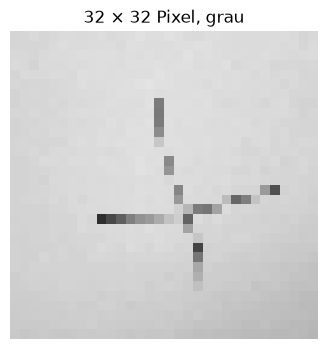

True

In [7]:
# >>> LOESUNG
# GELB| # Schritt 1: Wandeln Sie "bild" in ein Graustufenbild um.
# GELB| grau = None
# GELB|
# GELB| # Schritt 2: Verkleinern Sie "grau" auf 32 x 32 Pixel.
# GELB| klein = None
# | grau = None     # TODO: Bild in Graustufen umwandeln
# | klein = None    # TODO: auf 32 x 32 Pixel verkleinern
grau = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)     # Schritt 1: Farbbild -> Graustufenbild
klein = cv2.resize(grau, (32, 32))                # Schritt 2: auf 32 x 32 Pixel verkleinern
# <<< LOESUNG

kh.zeige_bild(klein, "32 × 32 Pixel, grau")
kh.pruefe_form(klein, (32, 32), "klein")

### [Frage]
1. Wie viele Zahlen hat das Bild `klein` noch? Vergleichen Sie mit dem Originalbild.
2. Kann man das Symbol auf dem kleinen Bild noch erkennen?
3. Warum ist ein kleines Bild für die KI und für den Raspberry Pi günstiger?

*Ihre Antworten:*

### [Aufgabe B2] Alle Bilder laden
Jetzt machen wir dasselbe mit **allen** Bildern. Wir sammeln sie in zwei Listen:
- `X` – die verkleinerten Bilder
- `y` – die Klassennummer zu jedem Bild (0 = Kreuz, 1 = Kreis, …)

`kh.alle_bilder(DATENSATZ)` liefert nacheinander jede Bilddatei zusammen mit ihrer Klassennummer.

**Befehle, die Sie brauchen:**
- Bild laden: `bild = cv2.imread(str(datei))`
- an eine Liste anhängen: `X.append(klein)` bzw. `y.append(klasse)`
- dazu die beiden Befehle aus Aufgabe B1

Schreiben Sie unter jede Kommentarzeile eine Zeile Python-Code. Achten Sie auf die Einrückung (4 Leerzeichen). Löschen Sie am Ende die Zeile `pass`.

Ergänzen Sie den Schleifenrumpf: Jedes Bild laden, grau machen, auf 32 × 32 verkleinern und mit seiner Klassennummer an `X` und `y` anhängen.

X hat die Form (176, 32, 32)   y hat die Form (176,)


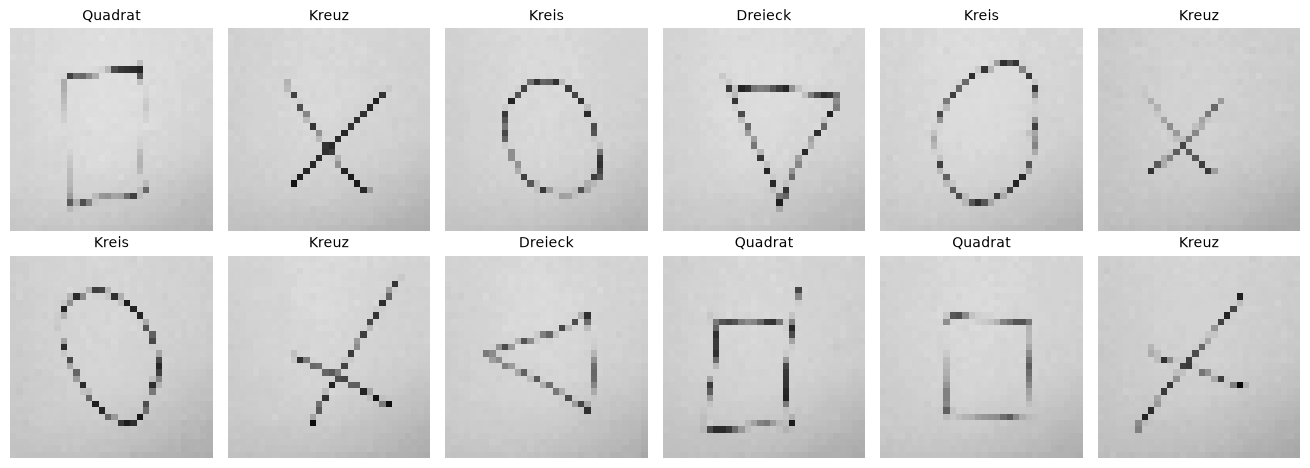

In [8]:
X = []      # Liste für die Bilder
y = []      # Liste für die Klassennummern (Labels)

for datei, klasse in kh.alle_bilder(DATENSATZ):
    # >>> LOESUNG
    # GELB| # Bild aus der Datei laden
    # GELB| # Bild in Graustufen umwandeln
    # GELB| # Bild auf 32 x 32 Pixel verkleinern
    # GELB| # das kleine Bild an die Liste X anhängen
    # GELB| # die Klassennummer an die Liste y anhängen
    # GELB| pass
    # | pass    # TODO
    bild = cv2.imread(str(datei))                     # Bild laden
    grau = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)     # grau machen
    klein = cv2.resize(grau, (32, 32))                # verkleinern
    X.append(klein)                                   # Bild merken
    y.append(klasse)                                  # Klassennummer merken
    # <<< LOESUNG

X = np.array(X)     # Listen in NumPy-Arrays umwandeln
y = np.array(y)
print("X hat die Form", X.shape, "  y hat die Form", y.shape)

kh.pruefe_gleich(len(X), len(kh.alle_bilder(DATENSATZ)), "Anzahl geladener Bilder")
kh.zeige_beispiele(X, y, klassen)

### [Frage]
1. Was bedeuten die drei Zahlen in der Form von `X`?
2. Welche Klassennummer hat ein Dreieck?

*Ihre Antworten:*

### [Aufgabe B3] Normieren
Neuronale Netze lernen besser mit kleinen Zahlen. Wir teilen deshalb jeden Pixelwert durch 255. Dann liegen alle Werte zwischen **0 und 1**.

**Befehl:** Ein ganzes Array teilt man wie eine Zahl: `X / 255`

In [9]:
# >>> LOESUNG
# GELB| # Teilen Sie X durch 255 und speichern Sie das Ergebnis in X_norm.
# GELB| X_norm = None
# | X_norm = None    # TODO: Werte auf 0 ... 1 bringen
X_norm = X / 255          # aus 0 ... 255 wird 0 ... 1
# <<< LOESUNG

kh.pruefe_bereich(X_norm, 0, 1, "X_norm")

True

### [Lesen] Trainings-, Validierungs- und Testdaten
![Datensplit](../material/bilder/datensplit.svg)

Die **Testbilder** sieht die KI während des Trainings nie. Nur so können wir am Ende ehrlich prüfen, ob sie auch **neue** Bilder richtig erkennt – genau wie später an der Prüfstation.

In [10]:
X_train, X_val, X_test, y_train, y_val, y_test = kh.teile_datensatz(X_norm, y)

print("Trainingsbilder:  ", len(X_train))
print("Validierungsbilder:", len(X_val))
print("Testbilder:       ", len(X_test))

Trainingsbilder:   123
Validierungsbilder: 26
Testbilder:        27


### [Frage]
1. Warum darf die KI die Testbilder beim Lernen nicht sehen? Denken Sie an eine Klassenarbeit.
2. Wie viel Prozent der Bilder sind Trainingsbilder?

*Ihre Antworten:*

### [Test] Teilzielkontrolle 1

In [11]:
kh.zeige_html("tzk1_daten_und_bilder.html")

---
## Teil C – Vom Neuron zum Netz (Doppelstunde 3)

### [Lesen] Das künstliche Neuron

In [12]:
kh.zeige_html("02_neuron.html")

### [Lesen] Viele Neuronen ergeben ein Netz
Viele Neuronen nebeneinander bilden eine **Schicht** (in Keras: `Dense`). Jedes Neuron ist mit **jedem** Neuron der nächsten Schicht verbunden. Deshalb heißt dieses Netz **vollvernetzt** (FCNN). Vorne steht `Flatten`: Es macht aus der Bild-Matrix einen Vektor.

![FCNN](../material/bilder/fcnn.svg)

Die letzte Schicht hat **ein Neuron pro Klasse**. Die Aktivierung **Softmax** macht aus den Ausgaben Wahrscheinlichkeiten.

In [13]:
kh.zeige_html("03_softmax_verlust.html")

### [Lesen] Das Label als One-Hot-Vektor
Das Netz gibt für jedes Bild **vier** Wahrscheinlichkeiten aus. Damit man vergleichen kann, schreibt man auch die richtige Antwort als vier Zahlen: An der Stelle der richtigen Klasse steht eine 1, sonst 0.

| Klasse | Nummer | One-Hot-Vektor |
|---|:--:|---|
| Kreuz | 0 | [1, 0, 0, 0] |
| Kreis | 1 | [0, 1, 0, 0] |
| Dreieck | 2 | ? |
| Quadrat | 3 | ? |

### [Aufgabe C1] One-Hot-Vektoren
Schreiben Sie die One-Hot-Vektoren für **Dreieck** und **Quadrat** als Python-Listen, z. B. `[1, 0, 0, 0]`.

In [14]:
# >>> LOESUNG
# GELB| # One-Hot-Vektor für Dreieck (Klasse 2) als Liste
# GELB| dreieck = None
# GELB| # One-Hot-Vektor für Quadrat (Klasse 3) als Liste
# GELB| quadrat = None
dreieck = [0, 0, 1, 0]
quadrat = [0, 0, 0, 1]
# <<< LOESUNG

kh.pruefe_gleich(dreieck, [0, 0, 1, 0], "dreieck")
kh.pruefe_gleich(quadrat, [0, 0, 0, 1], "quadrat")

True

### [Aufgabe C1] One-Hot-Kodierung
Schreiben Sie die Funktion `one_hot(labels, anzahl_klassen)`, die ein Array mit Klassennummern in eine One-Hot-Matrix umwandelt – ohne fertige Keras-Funktion. Hinweis: Zeile 2 von `np.eye(4)` ist `[0, 0, 1, 0]`.

In [15]:
def one_hot(labels, anzahl_klassen):
    # >>> LOESUNG
    # | return None   # TODO
    return np.eye(anzahl_klassen)[labels]
    # <<< LOESUNG

kh.pruefe_gleich(one_hot(np.array([2, 0]), 4), [[0, 0, 1, 0], [1, 0, 0, 0]], "one_hot([2, 0])")

True

Keras erledigt das Umwandeln für alle Labels mit einem Befehl. Führen Sie die Zelle aus. Dabei wird auch Keras geladen.

[Raspberry Pi] Das erste Laden von TensorFlow dauert 10 bis 30 Sekunden.

In [16]:
import keras
from keras import layers

ANZAHL_KLASSEN = len(klassen)                       # bei uns: 4
Y_train = keras.utils.to_categorical(y_train, ANZAHL_KLASSEN)
Y_val = keras.utils.to_categorical(y_val, ANZAHL_KLASSEN)
Y_test = keras.utils.to_categorical(y_test, ANZAHL_KLASSEN)

print("Label des ersten Trainingsbildes:", y_train[0], "->", Y_train[0])

Label des ersten Trainingsbildes: 0 -> [1. 0. 0. 0.]


### [Aufgabe C2] Das erste Netz bauen
So soll das Netz aussehen (wie in der Grafik oben):

| Schicht | Aufgabe |
|---|---|
| `keras.Input(shape=(32, 32))` | Eingang: ein Bild mit 32 × 32 Pixeln |
| `layers.Flatten()` | Matrix → Vektor mit 1024 Zahlen |
| `layers.Dense(64, activation="relu")` | Schicht mit 64 Neuronen |
| `layers.Dense(256, activation="relu")` | Schicht mit 256 Neuronen |
| `layers.Dense(128, activation="relu")` | Schicht mit 128 Neuronen |
| `layers.Dense(64, activation="relu")` | Schicht mit 64 Neuronen |
| `layers.Dense(ANZAHL_KLASSEN, activation="softmax")` | Ausgabe: eine Wahrscheinlichkeit je Klasse |

Das ist das Netz „medium“ aus dem Original-Notebook. In Notebook 11 vergleichen Sie es mit einem kleineren und einem größeren Netz.

**Befehl:** `layers.Dense(anzahl_neuronen, activation="relu"),` – das Komma am Ende jeder Zeile nicht vergessen.

Ergänzen Sie die vier versteckten Schichten und die Ausgabeschicht.

In [17]:
modell = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    # >>> LOESUNG
    # GELB| # Schicht mit 64 Neuronen, Aktivierung "relu"
    # GELB| # Schicht mit 256 Neuronen, Aktivierung "relu"
    # GELB| # Schicht mit 128 Neuronen, Aktivierung "relu"
    # GELB| # Schicht mit 64 Neuronen, Aktivierung "relu"
    # GELB| # Ausgabeschicht: ANZAHL_KLASSEN Neuronen, Aktivierung "softmax"
    # | # TODO: vier versteckte Schichten und die Ausgabeschicht
    layers.Dense(64, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(ANZAHL_KLASSEN, activation="softmax"),
    # <<< LOESUNG
])
modell.summary()

kh.pruefe_gleich(modell.output_shape, (None, ANZAHL_KLASSEN), "Ausgabe des Netzes")
kh.pruefe_gleich(modell.count_params(), 123652, "Anzahl Gewichte")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 123,652 (483.02 KB)

 Trainable params: 123,652 (483.02 KB)

 Non-trainable params: 0 (0.00 B)

True

### [Frage]
1. Die erste `Dense`-Schicht hat 65 600 Gewichte. Rechnen Sie nach: 1024 Eingänge × 64 Neuronen + 64 Bias-Gewichte.
2. Welche Schicht hat die meisten Gewichte? Was würde bei einem großen Kamerabild (640 × 480) passieren?

*Ihre Antworten:*

---
## Teil D – Das Netz trainieren (Doppelstunde 4)

### [Lesen] Wie lernt das Netz?

In [18]:
kh.zeige_html("04_gradientenabstieg.html")

### [Aufgabe D1] Das Training einstellen
Vor dem Training legt man drei Dinge fest:

| Einstellung | Bedeutung | Unsere Wahl |
|---|---|---|
| `optimizer` | Verfahren, das die Gewichte verbessert | `keras.optimizers.Adam(learning_rate=0.0003)` |
| `loss` | misst, wie falsch das Netz liegt | `"categorical_crossentropy"` |
| `metrics` | Kennzahl für uns Menschen | `["accuracy"]` (Anteil richtiger Antworten) |

Ersetzen Sie jedes `None` durch den Wert aus der Tabelle.

Kompilieren Sie das Modell mit den Werten aus der Tabelle.

In [19]:
# >>> LOESUNG
# GELB| modell.compile(
# GELB|     optimizer=None,   # Adam mit Lernrate 0.0003
# GELB|     loss=None,        # Verlustfunktion aus der Tabelle
# GELB|     metrics=None,     # Kennzahl aus der Tabelle
# GELB| )
# | # TODO: modell.compile(...)
modell.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
# <<< LOESUNG
print("Modell ist bereit zum Training.")

Modell ist bereit zum Training.


### [Aufgabe] Trainieren
`fit` zeigt dem Netz die Trainingsbilder 150-mal (150 **Epochen**), jeweils in Stapeln zu 32 Bildern. Nach jeder Epoche wird mit den Validierungsbildern geprüft, wie gut es schon ist.

Training läuft – bitte etwa 1 Minute warten ...
Fertig!


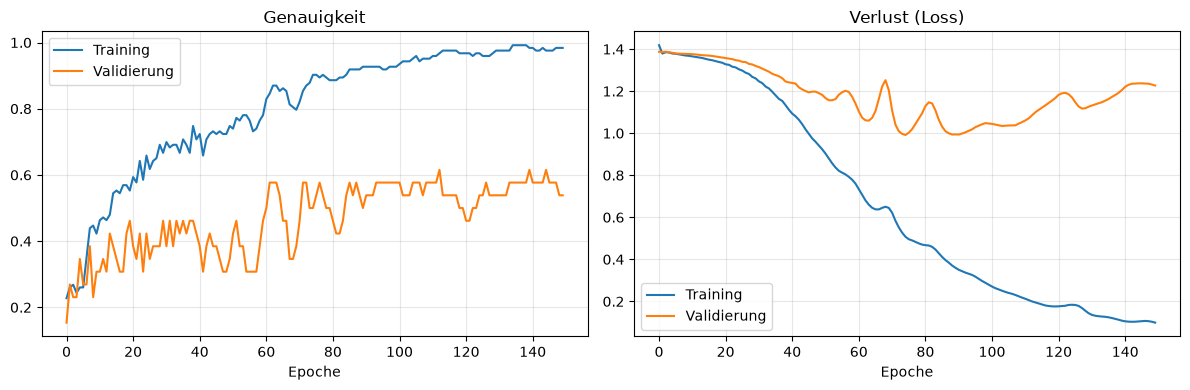

In [20]:
print("Training läuft – bitte etwa 1 Minute warten ...")
verlauf = modell.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                     epochs=150, batch_size=32, verbose=0)
print("Fertig!")
kh.zeige_lernkurven(verlauf)

### [Frage]
1. Wie entwickelt sich die Genauigkeit (blau: Training, orange: Validierung)?
2. Liegen die beiden Kurven nah beieinander oder gibt es eine Lücke? Was könnte eine Lücke bedeuten?

*Ihre Antworten:*

### [Aufgabe] Mit den Testbildern prüfen
Erst jetzt kommen die Testbilder zum Einsatz. Die **Konfusionsmatrix** zeigt, welche Formen verwechselt werden: Zeile = richtige Form, Spalte = Antwort der KI.

Genauigkeit auf den Testbildern: 52 %


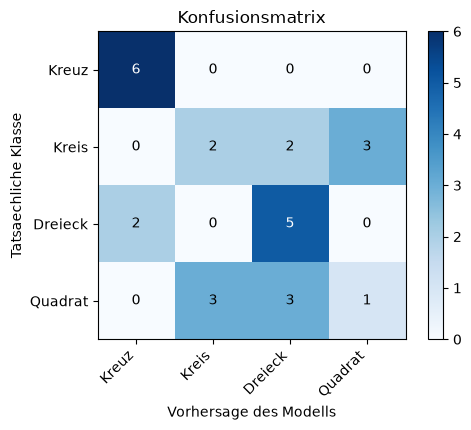

              precision    recall  f1-score   support

       Kreuz      0.750     1.000     0.857         6
       Kreis      0.400     0.286     0.333         7
     Dreieck      0.500     0.714     0.588         7
     Quadrat      0.250     0.143     0.182         7

    accuracy                          0.519        27
   macro avg      0.475     0.536     0.490        27
weighted avg      0.465     0.519     0.477        27



array([[6, 0, 0, 0],
       [0, 2, 2, 3],
       [2, 0, 5, 0],
       [0, 3, 3, 1]])

In [21]:
verlust, genauigkeit = modell.evaluate(X_test, Y_test, verbose=0)
print("Genauigkeit auf den Testbildern:", round(genauigkeit * 100), "%")

vorhersagen = modell.predict(X_test, verbose=0).argmax(axis=1)
kh.zeige_konfusionsmatrix(y_test, vorhersagen, klassen)

### [Aufgabe D2] Ein einzelnes Bild erkennen
An der Prüfstation kommt immer **ein** Bild. `modell.predict` erwartet aber einen **Stapel** von Bildern. Deshalb packen wir das eine Bild in einen Stapel: `np.array([einzelbild])`.

**Befehle, die Sie brauchen:**
- Bild in einen Stapel packen: `np.array([einzelbild])`
- Vorhersage für den Stapel, erstes Ergebnis nehmen: `modell.predict(stapel, verbose=0)[0]`
- Nummer der größten Wahrscheinlichkeit: `np.argmax(wahrscheinlichkeiten)`

Berechnen Sie für `X_test[nr]` die Wahrscheinlichkeiten aller Klassen und die Nummer der erkannten Klasse.

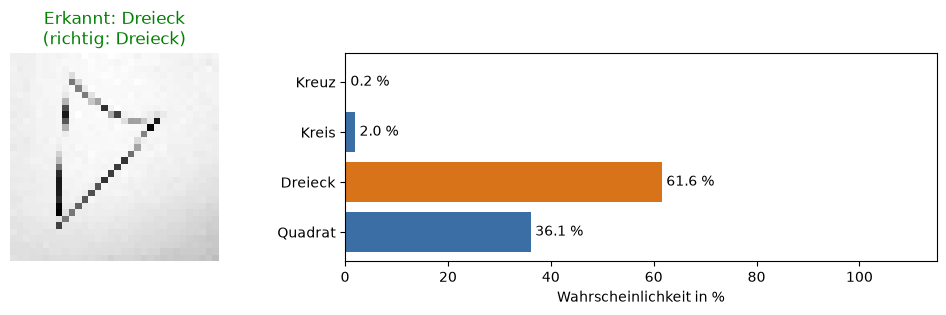

True

In [22]:
nr = 0                          # Nummer des Testbildes – ändern Sie die Zahl!
einzelbild = X_test[nr]

# >>> LOESUNG
# GELB| # Schritt 1: das Einzelbild in einen Stapel packen
# GELB| stapel = None
# GELB| # Schritt 2: Wahrscheinlichkeiten für den Stapel berechnen (erstes Ergebnis nehmen)
# GELB| wahrscheinlichkeiten = None
# GELB| # Schritt 3: Nummer der Klasse mit der größten Wahrscheinlichkeit bestimmen
# GELB| vorhersage = None
# | wahrscheinlichkeiten = None   # TODO
# | vorhersage = None             # TODO
stapel = np.array([einzelbild])                            # Stapel mit einem Bild
wahrscheinlichkeiten = modell.predict(stapel, verbose=0)[0]
vorhersage = np.argmax(wahrscheinlichkeiten)               # Nummer der größten Zahl
# <<< LOESUNG

kh.zeige_vorhersage(einzelbild, wahrscheinlichkeiten, klassen, richtig=y_test[nr])
kh.pruefe_gleich(vorhersage, vorhersagen[nr], "erkannte Klassennummer")

### [Frage]
1. Probieren Sie mehrere Bildnummern aus. Finden Sie ein Bild, das falsch erkannt wird? Woran könnte es liegen?
2. Wie sicher war sich die KI bei einem falsch erkannten Bild?

*Ihre Antworten:*

### [Aufgabe D3] Experimentieren
Ändern Sie **jeweils nur eine** Sache, führen Sie die Zellen ab Aufgabe C2 noch einmal aus und tragen Sie die Test-Genauigkeit ein.

| Versuch | Änderung | Test-Genauigkeit | Beobachtung |
|---|---|---|---|
| 0 | wie oben (64 / 256 / 128 / 64 Neuronen, Lernrate 0,0003, 150 Epochen) | | |
| 1 | nur **eine** Schicht mit 16 Neuronen | | |
| 2 | nach jeder versteckten Schicht `layers.Dropout(0.2),` einfügen (schaltet beim Lernen zufällig 20 % der Neuronen ab) | | |
| 3 | Lernrate 0,01 | | |
| 4 | Lernrate 0,000001 | | |
| 5 | großer Datensatz: `DATENSATZ = "dataset"` (ganz oben ändern) | | |

### Zusammenfassung
- Ein Bild ist für die KI eine Tabelle aus Zahlen. Wir haben die Bilder verkleinert, normiert und aufgeteilt.
- Ein neuronales Netz lernt, indem es seine Gewichte Schritt für Schritt so verändert, dass der Fehler kleiner wird.
- Das FCNN behandelt jedes Pixel einzeln und hat sehr viele Gewichte. In Notebook 11 verbessern wir das Training, in Notebook 12 lernen Sie ein Netz kennen, das für Bilder besser geeignet ist.

In [23]:
kh.ram_aufraeumen()     # Arbeitsspeicher freigeben